In [ ]:
# SEL 0 - Load data (Google Colab)
from google.colab import files
import pandas as pd

uploaded = files.upload()
df = pd.read_excel(list(uploaded.keys())[0])
df.head()

Saving 3TIC_07_PermintaanBarangMingguan.xlsx to 3TIC_07_PermintaanBarangMingguan.xlsx


,Nama_Barang,No_Faktur,Tgl_Faktur,Kuantitas,Unit,Jumlah
0,ASCO CROISSANT 3pac COKLAT,P25-2809,2025-08-11,3,pac,45045.00
1,ASCO CROISSANT 3pac COKLAT,P25-2811,2025-08-11,3,pac,45045.00
2,ASCO CROISSANT 3pac COKLAT,P25-2813,2025-08-11,9,pac,133783.78
3,ASCO CROISSANT 3pac COKLAT,P25-2814,2025-08-11,9,pac,133783.78
4,ASCO CROISSANT 3pac COKLAT,P25-2815,2025-08-11,3,pac,45045.07


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23140 entries, 0 to 23139
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Nama_Barang  23140 non-null  object        
 1   No_Faktur    23140 non-null  object        
 2   Tgl_Faktur   23140 non-null  datetime64[ns]
 3   Kuantitas    23140 non-null  int64         
 4   Unit         23140 non-null  object        
 5   Jumlah       23140 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(3)
memory usage: 1.1+ MB


In [ ]:
# SEL 1 - Format & kelengkapan data (Bab 3.3)
import pandas as pd

df['Tgl_Faktur'] = pd.to_datetime(df['Tgl_Faktur'], errors='coerce')
df['Kuantitas']  = pd.to_numeric(df['Kuantitas'], errors='coerce')
print("Kosong sebelum dibersihkan:\n", df[['Tgl_Faktur', 'Kuantitas']].isna().sum().to_string())
df = df.dropna(subset=['Tgl_Faktur', 'Kuantitas'])

# Hanya faktur penjualan ke toko. Isi bila ada kolom jenis transaksi:
# KOL_JENIS, JENIS_DIHITUNG = 'Jenis_Faktur', ['Penjualan']
# df = df[df[KOL_JENIS].isin(JENIS_DIHITUNG)]

print("Data setelah format & hapus kosong:", len(df))
df.head()

NameError: name 'df' is not defined

In [ ]:
#================== REVISI ====================



In [ ]:
# SEL 2 - Pra-pemrosesan, pengelompokan mingguan, deskriptif (Bab 3.3 - 3.4)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
try:
    display
except NameError:
    display = print

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.4})

# Pra-pemrosesan (Bab 3.3)
print("Data awal        :", len(df))
print("Rentang tanggal  :", df['Tgl_Faktur'].min().date(), "-", df['Tgl_Faktur'].max().date())
print("Kosong Tgl_Faktur:", df['Tgl_Faktur'].isna().sum())
print("Kosong Kuantitas :", df['Kuantitas'].isna().sum())
print("Tipe             :", df['Tgl_Faktur'].dtype, "|", df['Kuantitas'].dtype)
print("Duplikat         :", df.duplicated().sum())
print("Kuantitas <= 0   :", (df['Kuantitas'] <= 0).sum(), "(retur, dikeluarkan)")
print(df['Unit'].value_counts().head(), "\n")

d = df.drop_duplicates()
d = d[d['Kuantitas'] > 0]
print("Data akhir       :", len(d))

print("Jumlah <= 0:", (d['Jumlah'] <= 0).sum())
hrg = d['Jumlah'] / d['Kuantitas']
print(hrg.describe())

# Pengelompokan mingguan (Senin-Minggu)
d = d.assign(Minggu=d['Tgl_Faktur'].dt.to_period('W-SUN'))
mg = d.groupby('Minggu')['Kuantitas'].sum()
semua = pd.period_range(mg.index.min(), mg.index.max(), freq='W-SUN')
mg = mg.reindex(semua, fill_value=0)
print("\nMinggu pertama & terakhir (cek parsial):")
print(mg.head(2)); print(mg.tail(2))

mg = mg.iloc[1:-1]
x = mg.values.astype(float); n = len(x)
tgl = mg.index.start_time
print("\nn minggu:", n)
if n != 51:
    print(f"PERINGATAN: n = {n}, bukan 51")

# Pencilan (aturan IQR; diperiksa, tidak otomatis dibuang)
q1, q3 = np.quantile(x, [.25, .75]); iqr = q3 - q1
print(f"\nBatas IQR: < {q1-1.5*iqr:,.0f} atau > {q3+1.5*iqr:,.0f}")
print("Minggu pencilan:\n", mg[(mg < q1-1.5*iqr) | (mg > q3+1.5*iqr)])

# Deskriptif & asumsi
m, s2 = x.mean(), x.var(ddof=1); s = np.sqrt(s2)
print(f"\nMean {m:.2f} | Median {np.median(x):.2f} | Var {s2:,.2f} | SD {s:.2f}")
print(f"Min {x.min():.0f} | Q1 {q1:.0f} | Q3 {q3:.0f} | Max {x.max():.0f}")
print(f"CV {s/m*100:.2f}% | Skew {stats.skew(x, bias=False):.3f} | Kurt {stats.kurtosis(x, bias=False):.3f}")
print(f"Indeks dispersi I = s²/x̄ = {s2/m:.1f}")

print("\nUji Ljung-Box (lag 10):")
print(acorr_ljungbox(x, lags=[10], return_df=True))
reg = stats.linregress(np.arange(1, n+1), x)
print(f"Regresi tren: slope={reg.slope:.1f}, p={reg.pvalue:.4f}")

# Gambar 1: Tren
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(tgl, x, marker='o', ms=4, lw=1.6, label='Permintaan mingguan')
ax.axhline(m, color='tab:red', ls='--', label=f'Rata-rata ({m:,.0f})')
ax.plot(tgl, reg.intercept + reg.slope*np.arange(1, n+1), color='gray', lw=1.2, label='Garis tren')
ax.set(title='Tren Permintaan Barang Mingguan', xlabel='Minggu', ylabel='Total Kuantitas')
ax.legend(); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

# Gambar 2: Histogram
bins = int(np.ceil(1 + np.log2(n)))
plt.figure(figsize=(9, 5))
plt.hist(x, bins=bins, edgecolor='black', color='tab:blue', alpha=0.8)
plt.axvline(m, color='tab:red', ls='--', label='Rata-rata')
plt.axvline(np.median(x), color='tab:green', ls='--', label='Median')
plt.title(f'Distribusi Permintaan Mingguan (bins = {bins}, Sturges)')
plt.xlabel('Total Kuantitas per Minggu'); plt.ylabel('Frekuensi'); plt.legend()
plt.tight_layout(); plt.show()

# Gambar 3: Boxplot
plt.figure(figsize=(9, 3.5))
plt.boxplot(x, vert=False, showmeans=True, patch_artist=True,
            boxprops=dict(facecolor='lightsteelblue'))
plt.title('Boxplot Permintaan Barang Mingguan'); plt.xlabel('Total Kuantitas per Minggu')
plt.yticks([]); plt.tight_layout(); plt.show()

# Gambar 4: CDF empiris
xs = np.sort(x); pe = np.arange(1, n+1)/n
plt.figure(figsize=(9, 5))
plt.step(xs, pe, where='post')
for g in (0.5, 0.9, 0.95, 0.99):
    plt.axhline(g, color='gray', ls=':', lw=0.9)
plt.title('CDF Empiris Permintaan Barang Mingguan')
plt.xlabel('Total Kuantitas per Minggu'); plt.ylabel('Probabilitas Kumulatif')
plt.tight_layout(); plt.show()

NameError: name 'df' is not defined

In [ ]:
#revisi - 2
# SEL 2 - Pra-pemrosesan, statistika deskriptif, uji t, stok (Bab 3.3 - 3.4)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats   # hanya untuk uji t (3.4.5)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True,
                     'grid.linestyle': '--', 'grid.alpha': 0.4})

# ===== Pra-pemrosesan (3.3) =====
print("Data awal        :", len(df))
print("Rentang tanggal  :", df['Tgl_Faktur'].min().date(), "-", df['Tgl_Faktur'].max().date())
print("Kosong Tgl_Faktur:", df['Tgl_Faktur'].isna().sum())
print("Kosong Kuantitas :", df['Kuantitas'].isna().sum())
print("Tipe             :", df['Tgl_Faktur'].dtype, "|", df['Kuantitas'].dtype)
print("Duplikat         :", df.duplicated().sum())
print("Kuantitas <= 0   :", (df['Kuantitas'] <= 0).sum(), "(retur, dikeluarkan)")

vc = df['Unit'].value_counts()
print("\nFrekuensi satuan (% dari data awal):")
print(pd.DataFrame({'baris': vc, 'persen': (vc/len(df)*100).round(2)}))

d = df.dropna(subset=['Tgl_Faktur', 'Kuantitas'])
d = d.drop_duplicates()
d = d[d['Kuantitas'] > 0]
print("\nData akhir       :", len(d))

print("Jumlah <= 0      :", (d['Jumlah'] <= 0).sum())
print((d['Jumlah'] / d['Kuantitas']).describe())

# ===== Pengelompokan mingguan Senin-Minggu (3.3f) =====
d = d.assign(Minggu=d['Tgl_Faktur'].dt.to_period('W-SUN'))
mg = d.groupby('Minggu')['Kuantitas'].sum()
semua = pd.period_range(mg.index.min(), mg.index.max(), freq='W-SUN')
mg = mg.reindex(semua, fill_value=0)
print("\nMinggu pertama & terakhir (cek parsial):")
print(mg.head(2)); print(mg.tail(2))

mg_penuh = mg.iloc[1:-1]                     # buang minggu parsial
x = mg_penuh.values.astype(float); n = len(x)
tgl = mg_penuh.index.start_time
print("\nn minggu:", n)
if n != 51:
    print(f"PERINGATAN: n = {n}, bukan 51")
print("Minggu bernilai rendah (<5000):\n", mg_penuh[mg_penuh < 5000])

# ===== Statistika deskriptif (3.4.1 - 3.4.3) =====
def ringkas(v):
    m = v.mean(); md = np.median(v); s = v.std(ddof=1)
    q1, q3 = np.quantile(v, [.25, .75])      # interpolasi linear (pers. 21)
    return {'n': len(v), 'Rata-rata': m, 'Median': md, 'Varians': v.var(ddof=1),
            'Simpangan baku': s, 'Minimum': v.min(), 'Maksimum': v.max(),
            'Rentang': v.max() - v.min(), 'Q1': q1, 'Q3': q3, 'IQR': q3 - q1,
            'CV (%)': s/m*100, 'Sk Pearson': 3*(m - md)/s}

hasil = ringkas(x)
print(f"\n=== Statistik deskriptif (n = {n}) ===")
for k, v in hasil.items():
    print(f"{k:15s}: {v:,.3f}")
m, q1, q3, iqr = hasil['Rata-rata'], hasil['Q1'], hasil['Q3'], hasil['IQR']

# ===== Pencilan: aturan IQR (3.3g) =====
bb, ba = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f"\nBatas IQR: < {bb:,.0f} atau > {ba:,.0f}")
print("Minggu pencilan:\n", mg_penuh[(mg_penuh < bb) | (mg_penuh > ba)])

# ===== Uji t Welch: paruh 1 vs paruh 2 (3.4.5) =====
h = n // 2
x1, x2 = x[:h], x[h:]                        # 25 dan 26 minggu
t_res = stats.ttest_ind(x1, x2, equal_var=False)
a, b = x1.var(ddof=1)/len(x1), x2.var(ddof=1)/len(x2)
df_w = (a + b)**2 / (a**2/(len(x1)-1) + b**2/(len(x2)-1))
print("\n=== Uji t Welch ===")
print(f"Paruh 1: n = {len(x1)}, rata-rata = {x1.mean():,.2f}")
print(f"Paruh 2: n = {len(x2)}, rata-rata = {x2.mean():,.2f}")
print(f"t = {t_res.statistic:.3f} | df = {df_w:.1f} | p = {t_res.pvalue:.4f}")
print("Keputusan (alpha = 0,05):",
      "tolak H0" if t_res.pvalue < 0.05 else "gagal tolak H0")

# ===== Penentuan stok dan evaluasi (3.4.6 - 3.4.7) =====
def tabel_stok(v):
    mv = v.mean(); baris = []
    for g in (0.90, 0.95, 0.99):
        sg = np.ceil(np.quantile(v, g))
        baris.append({'gamma': f"{g:.0%}", 's_gamma': sg, 'SS': sg - mv,
                      'prop_terpenuhi': (v <= sg).mean(),
                      'minggu_melampaui': int((v > sg).sum())})
    return pd.DataFrame(baris)

print(f"\n=== Stok berdasarkan persentil (n = {n}) ===")
print(tabel_stok(x).round(4).to_string(index=False))
print(f"Pembanding s = rata-rata: terpenuhi {(x <= m).mean():.2%}, "
      f"melampaui {int((x > m).sum())} minggu")
print(f"Rentang umum 95%: {np.quantile(x, .025):,.0f} - {np.quantile(x, .975):,.0f}")

# ===== Pembanding tanpa minggu libur, n = 50 (3.4.7) =====
libur = pd.Period('2025-03-31', freq='W-SUN')
x_tl = mg_penuh.drop(libur).values.astype(float)
print(f"\n=== Tanpa minggu libur (n = {len(x_tl)}) ===")
for k, v in ringkas(x_tl).items():
    print(f"{k:15s}: {v:,.3f}")
print(tabel_stok(x_tl).round(4).to_string(index=False))

# ===== Gambar 1: Grafik deret mingguan =====
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(tgl, x, marker='o', ms=4, lw=1.6, label='Permintaan mingguan')
ax.axhline(m, color='tab:red', ls='--', label=f'Rata-rata ({m:,.0f})')
ax.hlines(x1.mean(), tgl[0], tgl[h-1], color='tab:green', lw=2.5,
          label=f'Rata-rata paruh 1 ({x1.mean():,.0f})')
ax.hlines(x2.mean(), tgl[h], tgl[-1], color='tab:orange', lw=2.5,
          label=f'Rata-rata paruh 2 ({x2.mean():,.0f})')
ax.set(title='Grafik Deret Permintaan Barang Mingguan',
       xlabel='Minggu', ylabel='Total Kuantitas')
ax.legend(); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

# ===== Gambar 2: Histogram (Sturges) =====
k = int(np.ceil(1 + np.log2(n)))
print(f"\nKelas Sturges k = {k}, lebar kelas = {(x.max()-x.min())/k:,.0f}")
plt.figure(figsize=(9, 5))
plt.hist(x, bins=k, edgecolor='black', color='tab:blue', alpha=0.8)
plt.axvline(m, color='tab:red', ls='--', label='Rata-rata')
plt.axvline(np.median(x), color='tab:green', ls='--', label='Median')
plt.title(f'Histogram Permintaan Mingguan (k = {k}, Sturges)')
plt.xlabel('Total Kuantitas per Minggu'); plt.ylabel('Frekuensi'); plt.legend()
plt.tight_layout(); plt.show()

# ===== Gambar 3: Boxplot =====
plt.figure(figsize=(9, 3.5))
plt.boxplot(x, vert=False, whis=1.5, showmeans=True, patch_artist=True,
            boxprops=dict(facecolor='lightsteelblue'))
plt.title('Boxplot Permintaan Barang Mingguan')
plt.xlabel('Total Kuantitas per Minggu')
plt.yticks([]); plt.tight_layout(); plt.show()

# ===== Gambar 4: Ogive =====
xs = np.sort(x); pe = np.arange(1, n+1)/n
plt.figure(figsize=(9, 5))
plt.step(xs, pe, where='post')
for g in (0.90, 0.95, 0.99):
    plt.axhline(g, color='gray', ls=':', lw=0.9)
    plt.axvline(np.ceil(np.quantile(x, g)), color='tab:red', ls=':', lw=0.9)
plt.title('Ogive (Distribusi Frekuensi Kumulatif Relatif) Permintaan Mingguan')
plt.xlabel('Total Kuantitas per Minggu'); plt.ylabel('F(x)')
plt.tight_layout(); plt.show()

In [ ]:
# SEL 3 - Estimasi parameter & uji kecocokan (bootstrap parametrik)
def fit(nama, v):
    mu, var = v.mean(), v.var(ddof=1)
    if nama == 'Normal':  return stats.norm(mu, np.sqrt(var))
    if nama == 'Poisson': return stats.poisson(mu)
    if var > mu:          return stats.nbinom(mu**2/(var-mu), mu/var)
    return stats.poisson(mu)

def n_param(nama, v):
    if nama == 'Normal':  return 2
    if nama == 'Poisson': return 1
    return 2 if v.var(ddof=1) > v.mean() else 1

def stat_ks(v, dist):
    xs_ = np.sort(v); F = dist.cdf(xs_); i = np.arange(1, len(xs_)+1)
    return max((i/len(xs_) - F).max(), (F - (i-1)/len(xs_)).max())

K = 6
def stat_chi2(v, dist, k=K):
    u = np.clip(np.floor(dist.cdf(v)*k).astype(int), 0, k-1)
    O = np.bincount(u, minlength=k); E = len(v)/k
    return ((O-E)**2/E).sum()

B = 5000          # turunkan ke 500 untuk uji coba
NAMA = ['Normal', 'Poisson', 'Binomial Negatif']

def uji_gof(v, B=B, seed=42):
    r = np.random.default_rng(seed)          # seed tetap -> hasil reproducible
    nn, hasil = len(v), []
    for nama in NAMA:
        dist = fit(nama, v)
        ks0, c0 = stat_ks(v, dist), stat_chi2(v, dist)
        ks_s, c_s = [], []
        for _ in range(B):
            xb = dist.rvs(size=nn, random_state=r)
            db = fit(nama, xb)               # estimasi ulang parameter
            ks_s.append(stat_ks(xb, db)); c_s.append(stat_chi2(xb, db))
        hasil.append([nama, ks0, (np.sum(np.array(ks_s) >= ks0)+1)/(B+1),
                      c0, (np.sum(np.array(c_s) >= c0)+1)/(B+1)])
    g_ = pd.DataFrame(hasil, columns=['Distribusi','D (K-S)','p K-S','Chi²','p Chi²'])
    g_['m']  = [n_param(nm, v) for nm in g_['Distribusi']]
    g_['df'] = K - 1 - g_['m']
    g_['p Chi² (df)'] = stats.chi2.sf(g_['Chi²'].values, g_['df'].values)
    g_['Lolos'] = (g_['p K-S'] >= 0.05) & (g_['p Chi²'] >= 0.05)
    return g_

def pilih(g_):
    """Kriteria 3.4: lolos kedua uji; bila >1: urutan p sama -> p terbesar,
    urutan beda -> yang paling mudah untuk stok pengaman (Normal > Poisson > NB).
    Syarat visual (Gambar 5-7) tetap dinilai manual."""
    ok = g_[g_['Lolos']]
    if ok.empty: return None
    if len(ok) == 1: return ok.iloc[0]['Distribusi']
    if (ok['p K-S'].rank(ascending=False) == ok['p Chi²'].rank(ascending=False)).all():
        return ok.loc[ok['p K-S'].idxmax(), 'Distribusi']
    for nm in NAMA:
        if nm in set(ok['Distribusi']): return nm

gof = uji_gof(x)
display(gof.round(4))
saran = pilih(gof)
print("Saran distribusi (otomatis):", saran if saran else "TIDAK ADA yang lolos -> laporkan apa adanya")

,Distribusi,D (K-S),p K-S,Chi²,p Chi²,m,df,p Chi² (df),Lolos
0,Normal,0.0819,0.5277,2.7647,0.5509,2,3,0.4293,True
1,Poisson,0.5294,0.0002,98.2941,0.0002,1,4,0.0000,False
2,Binomial Negatif,0.0716,0.7367,3.0000,0.5273,2,3,0.3916,True


Saran distribusi (otomatis): Normal


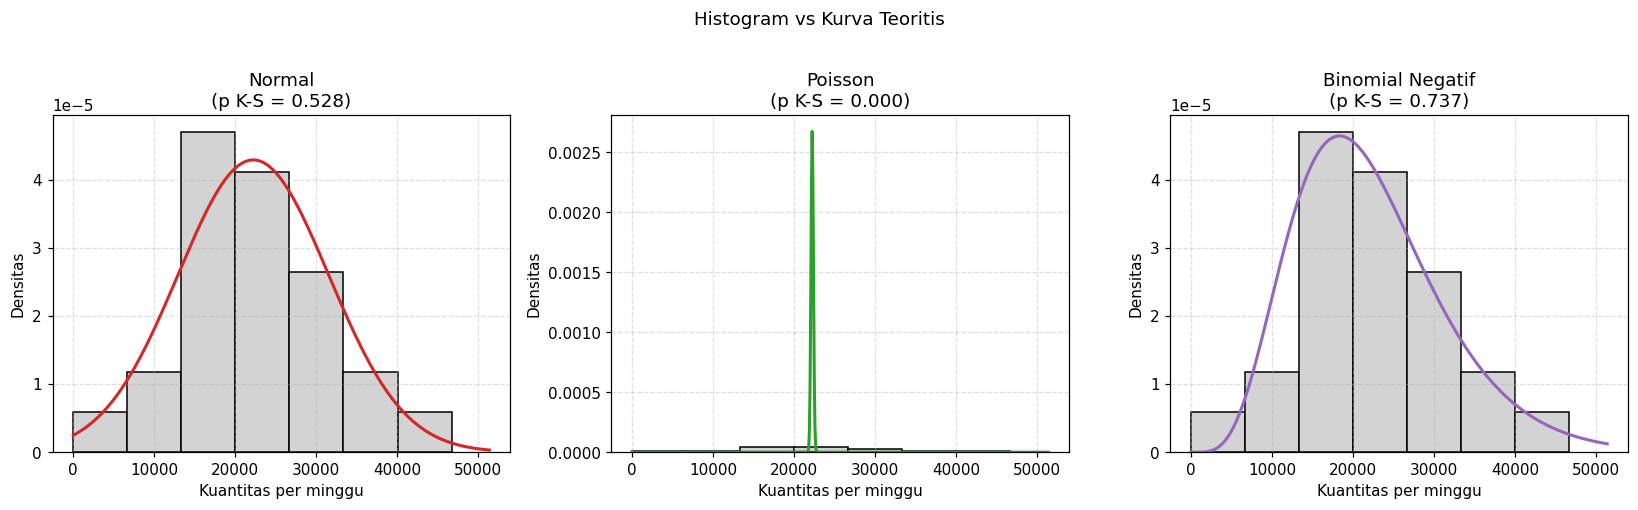

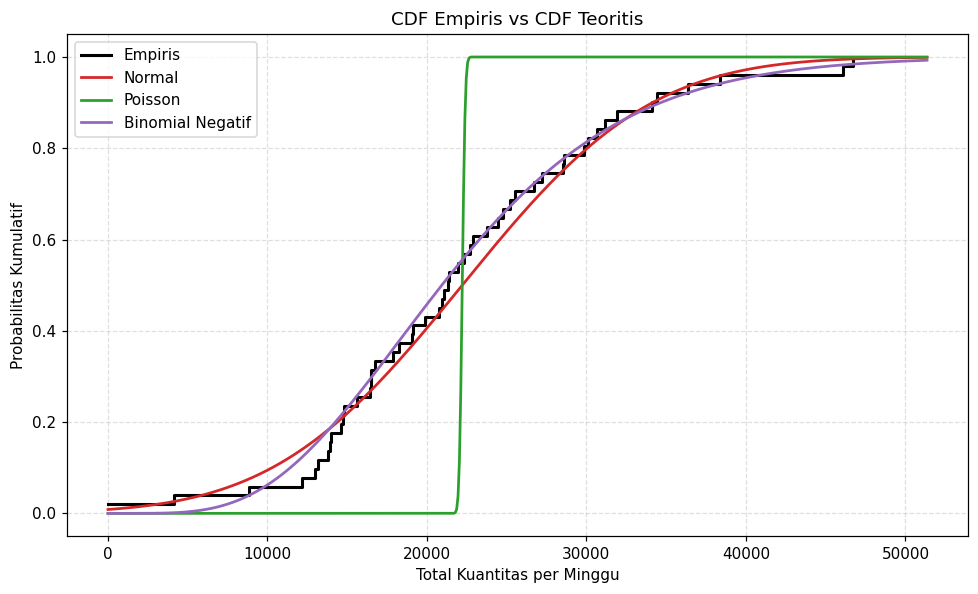

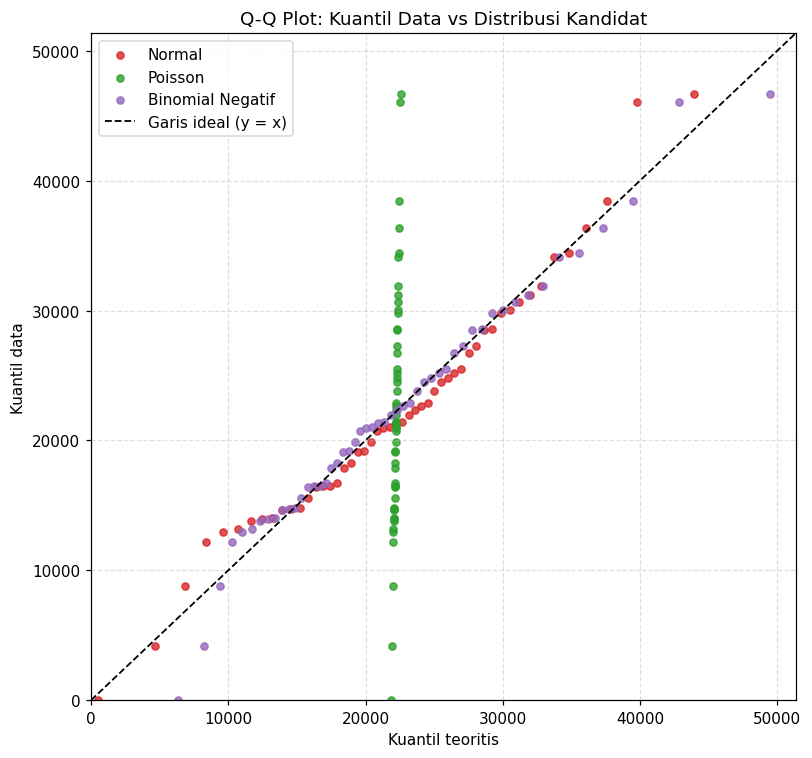

In [ ]:
# SEL 4 - Gambar 5-7 (pemeriksaan visual)
warna = {'Normal': 'tab:red', 'Poisson': 'tab:green', 'Binomial Negatif': 'tab:purple'}
dists = {k_: fit(k_, x) for k_ in NAMA}
grid = np.linspace(max(0, x.min()*0.8), x.max()*1.1, 600)

# Gambar 5: Histogram + kurva teoritis
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, nama in zip(axs, NAMA):
    ax.hist(x, bins=bins, density=True, color='lightgray', edgecolor='black')
    dd = dists[nama]
    y = dd.pdf(grid) if nama == 'Normal' else dd.pmf(np.round(grid))
    ax.plot(grid, y, color=warna[nama], lw=2)
    ax.set_title(f'{nama}\n(p K-S = {gof.loc[gof.Distribusi==nama,"p K-S"].values[0]:.3f})')
    ax.set_xlabel('Kuantitas per minggu'); ax.set_ylabel('Densitas')
plt.suptitle('Histogram vs Kurva Teoritis', y=1.02); plt.tight_layout(); plt.show()

# Gambar 6: CDF empiris vs teoritis
plt.figure(figsize=(9, 5.5))
plt.step(xs, pe, where='post', color='black', lw=2, label='Empiris')
for nama in NAMA:
    plt.plot(grid, dists[nama].cdf(grid), color=warna[nama], lw=1.8, label=nama)
plt.title('CDF Empiris vs CDF Teoritis'); plt.xlabel('Total Kuantitas per Minggu')
plt.ylabel('Probabilitas Kumulatif'); plt.legend(); plt.tight_layout(); plt.show()

# Gambar 7: Q-Q plot
pp = (np.arange(1, n+1) - 0.5)/n
plt.figure(figsize=(7.5, 7))
for nama in NAMA:
    plt.scatter(dists[nama].ppf(pp), xs, s=22, color=warna[nama], alpha=0.8, label=nama)
lim = [0, x.max()*1.1]
plt.plot(lim, lim, 'k--', lw=1.2, label='Garis ideal (y = x)')
plt.xlim(lim); plt.ylim(lim)
plt.title('Q-Q Plot: Kuantil Data vs Distribusi Kandidat')
plt.xlabel('Kuantil teoritis'); plt.ylabel('Kuantil data'); plt.legend()
plt.tight_layout(); plt.show()

Distribusi terpilih: Normal
CI 95% rata-rata: 19,599 - 24,833


,Persentil,Normal,Empiris
0,0.0,3981.0,4140.0
1,0.0,22216.0,21317.0
2,1.0,40452.0,46063.0


,γ,Batas (Normal),Batas (Empiris),Safety Stock
0,90%,34140.0,34086.0,11924.0
1,95%,37520.0,38396.0,15304.0
2,99%,43861.0,46686.0,21645.0


E(X) = 22,216


,γ,s_γ,P(X > s)
0,0.90,34140.0,0.10
1,0.95,37520.0,0.05
2,0.99,43861.0,0.01


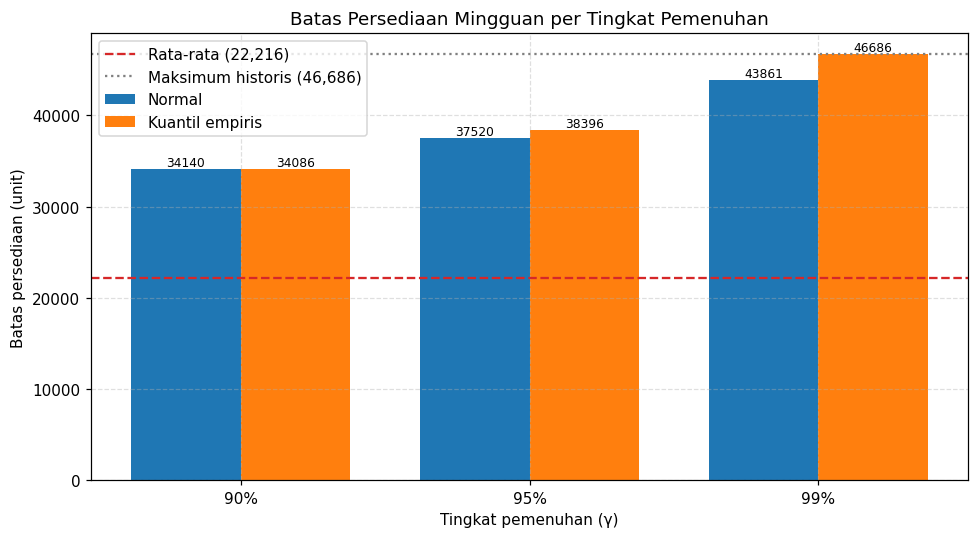

In [ ]:
# SEL 5 - Inferensial, stok, E(X), P(X > s)
TERPILIH_MANUAL = 'Normal'     # isi 'Normal' / 'Poisson' / 'Binomial Negatif' setelah cek Gambar 5-7
TERPILIH = TERPILIH_MANUAL or saran
if TERPILIH is None:
    TERPILIH = gof.loc[gof['p K-S'].idxmax(), 'Distribusi']
    print(f"PERINGATAN: tidak ada kandidat lolos. '{TERPILIH}' dipakai sementara; laporkan sebagai keterbatasan.")
print("Distribusi terpilih:", TERPILIH)

def stok(nama, v, g):
    if nama == 'Empiris':   return np.ceil(np.quantile(v, g, method='inverted_cdf'))
    if nama == 'Rata-rata': return np.ceil(v.mean())
    if nama == 'Normal_z':  return np.ceil(max(0, v.mean() + stats.norm.ppf(g)*v.std(ddof=1)))
    return np.ceil(max(0, fit(nama, v).ppf(g)))

# CI & persentil
ci = stats.t.interval(0.95, n-1, loc=m, scale=stats.sem(x))
print(f"CI 95% rata-rata: {ci[0]:,.0f} - {ci[1]:,.0f}")

pers = [0.025, 0.5, 0.975]
display(pd.DataFrame({'Persentil': pers,
    TERPILIH: [max(0, fit(TERPILIH, x).ppf(p)) for p in pers],
    'Empiris': np.quantile(x, pers, method='inverted_cdf')}).round(0))

# Stok per γ
G = (0.90, 0.95, 0.99)
tabel = pd.DataFrame({'γ': ['90%','95%','99%'],
    f'Batas ({TERPILIH})': [stok(TERPILIH, x, g) for g in G],
    'Batas (Empiris)':     [stok('Empiris', x, g) for g in G]})
tabel['Safety Stock'] = tabel[f'Batas ({TERPILIH})'] - m
display(tabel.round(0))

# E(X) dan P(X > s) (persamaan 13)
dist_t = fit(TERPILIH, x)
print(f"E(X) = {dist_t.mean():,.0f}")
pel = pd.DataFrame({'γ': G, 's_γ': [stok(TERPILIH, x, g) for g in G]})
pel['P(X > s)'] = dist_t.sf(pel['s_γ'].values)
display(pel.round(4))

# Gambar 8: Perbandingan batas persediaan
idx = np.arange(3); w = 0.38
plt.figure(figsize=(9, 5))
b1 = plt.bar(idx - w/2, tabel[f'Batas ({TERPILIH})'], w, label=TERPILIH, color='tab:blue')
b2 = plt.bar(idx + w/2, tabel['Batas (Empiris)'], w, label='Kuantil empiris', color='tab:orange')
plt.axhline(m, color='tab:red', ls='--', label=f'Rata-rata ({m:,.0f})')
plt.axhline(x.max(), color='gray', ls=':', label=f'Maksimum historis ({x.max():,.0f})')
plt.bar_label(b1, fmt='%.0f', fontsize=8); plt.bar_label(b2, fmt='%.0f', fontsize=8)
plt.xticks(idx, tabel['γ']); plt.xlabel('Tingkat pemenuhan (γ)'); plt.ylabel('Batas persediaan (unit)')
plt.title('Batas Persediaan Mingguan per Tingkat Pemenuhan'); plt.legend()
plt.tight_layout(); plt.show()

,Metode,γ,Service level aktual (%),Minggu kurang,p binomial,Fill rate (%),Rata² kekurangan,Rata² kelebihan
0,Rata-rata,0.50,54.90,23,NaN,83.66,3629.67,3630.20
1,Normal,0.90,88.24,6,0.64,96.88,692.20,12614.51
2,Empiris,0.90,88.24,6,0.64,96.07,873.31,12487.49
3,Normal,0.95,94.12,3,0.74,98.05,433.27,15735.33
4,Empiris,0.95,94.12,3,0.74,98.05,432.12,16492.71
5,Normal,0.99,96.08,2,0.09,99.23,170.06,21811.90
6,Empiris,0.99,98.04,1,0.40,99.95,12.22,24469.82


Catatan: untuk γ = 99%, < 1 minggu diharapkan melampaui stok dalam 51 minggu -> hanya dilaporkan.
Keterbatasan: distribusi dipilih sekali pada seluruh data -> hasil LOO bisa sedikit optimistis.


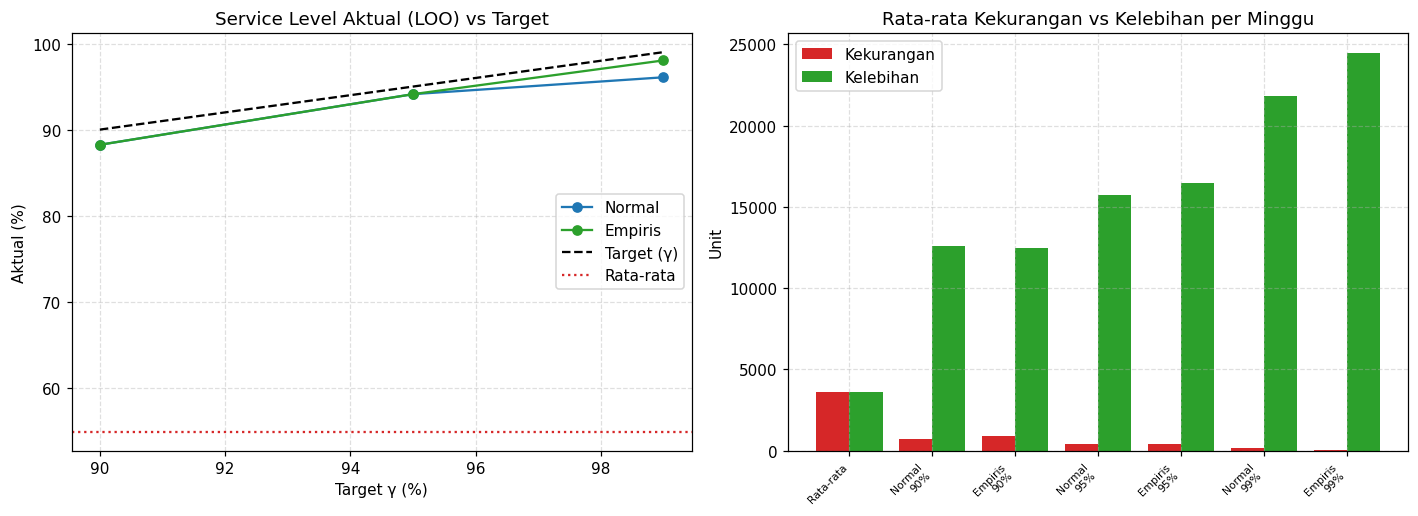

In [ ]:
# SEL 6 - Evaluasi leave-one-out + 3 pembanding (Bab 3.4 metode 6)
def loo(nama, g, v):
    nn = len(v)
    s_i = np.array([stok(nama, np.delete(v, i), g) for i in range(nn)])
    ok = v <= s_i
    p_bin = np.nan if nama == 'Rata-rata' else stats.binomtest(int(ok.sum()), nn, g).pvalue
    return [nama, g, ok.mean()*100, int((~ok).sum()), p_bin,
            (1 - np.maximum(v - s_i, 0).sum()/v.sum())*100,
            np.maximum(v - s_i, 0).mean(), np.maximum(s_i - v, 0).mean()]

def evaluasi(v, terpilih):
    metode = ([] if terpilih == 'Normal' else ['Normal_z']) + [terpilih, 'Empiris']
    baris = [loo('Rata-rata', 0.5, v)]          # pembanding s = x̄ (tanpa uji binomial)
    for g in G:
        for nama in metode:
            baris.append(loo(nama, g, v))
    return pd.DataFrame(baris, columns=['Metode','γ','Service level aktual (%)','Minggu kurang',
        'p binomial','Fill rate (%)','Rata² kekurangan','Rata² kelebihan'])

eva = evaluasi(x, TERPILIH)
display(eva.round(2))
print("Catatan: untuk γ = 99%, < 1 minggu diharapkan melampaui stok dalam 51 minggu -> hanya dilaporkan.")
print("Keterbatasan: distribusi dipilih sekali pada seluruh data -> hasil LOO bisa sedikit optimistis.")

# Gambar 9 & 10
sub = eva[eva['Metode'] != 'Rata-rata']
warna_m = dict(zip(dict.fromkeys(sub['Metode']), ['tab:blue', 'tab:green', 'tab:orange']))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for nama, c in warna_m.items():
    t = sub[sub.Metode == nama]
    axs[0].plot(t['γ']*100, t['Service level aktual (%)'], marker='o', color=c, label=nama)
axs[0].plot([90, 99], [90, 99], 'k--', label='Target (γ)')
axs[0].axhline(eva.iloc[0]['Service level aktual (%)'], color='tab:red', ls=':', label='Rata-rata')
axs[0].set(title='Service Level Aktual (LOO) vs Target', xlabel='Target γ (%)', ylabel='Aktual (%)')
axs[0].legend()
lab = [f"{r.Metode}\n{int(round(r['γ']*100))}%" if r.Metode != 'Rata-rata' else 'Rata-rata'
       for _, r in eva.iterrows()]
xi = np.arange(len(eva))
axs[1].bar(xi - 0.2, eva['Rata² kekurangan'], 0.4, label='Kekurangan', color='tab:red')
axs[1].bar(xi + 0.2, eva['Rata² kelebihan'], 0.4, label='Kelebihan', color='tab:green')
axs[1].set_xticks(xi); axs[1].set_xticklabels(lab, fontsize=7, rotation=45, ha='right')
axs[1].set(title='Rata-rata Kekurangan vs Kelebihan per Minggu', ylabel='Unit'); axs[1].legend()
plt.tight_layout(); plt.show()

Hari faktur sekitar libur: [datetime.date(2025, 3, 20), datetime.date(2025, 3, 21), datetime.date(2025, 3, 22), datetime.date(2025, 3, 24), datetime.date(2025, 3, 25), datetime.date(2025, 3, 26), datetime.date(2025, 3, 27), datetime.date(2025, 3, 28), datetime.date(2025, 4, 3), datetime.date(2025, 4, 7), datetime.date(2025, 4, 8), datetime.date(2025, 4, 9), datetime.date(2025, 4, 10)]
Baris faktur antara 2025-03-28 dan 2025-04-07: 3 (sangat sedikit -> minggu libur)

Minggu ditandai libur:
 2025-03-31/2025-04-06    9
Freq: W-SUN, Name: Kuantitas, dtype: int64

Semua minggu (51)  : mean 22,216, SD 9,304, I = 3896.5
Tanpa libur (50) : mean 22,660, SD 8,835, I = 3445.0
Ljung-Box p (semua)      : 0.3757
Ljung-Box p (tanpa libur): 0.4836


,Distribusi,D (K-S),p K-S,Chi²,p Chi²,m,df,p Chi² (df),Lolos
0,Normal,0.0905,0.3911,1.12,0.9012,2,3,0.7722,True
1,Poisson,0.5407,0.0002,97.12,0.0002,1,4,0.0000,False
2,Binomial Negatif,0.0597,0.9354,0.16,0.9970,2,3,0.9838,True


Saran distribusi tanpa libur: Binomial Negatif
Stok γ (semua minggu, Normal) : [34140.0, 37520.0, 43861.0]
Stok γ (tanpa libur, Binomial Negatif)  : [34463.0, 38874.0, 48084.0]
Stok γ (tanpa libur, Normal) : [33984.0, 37194.0, 43215.0]


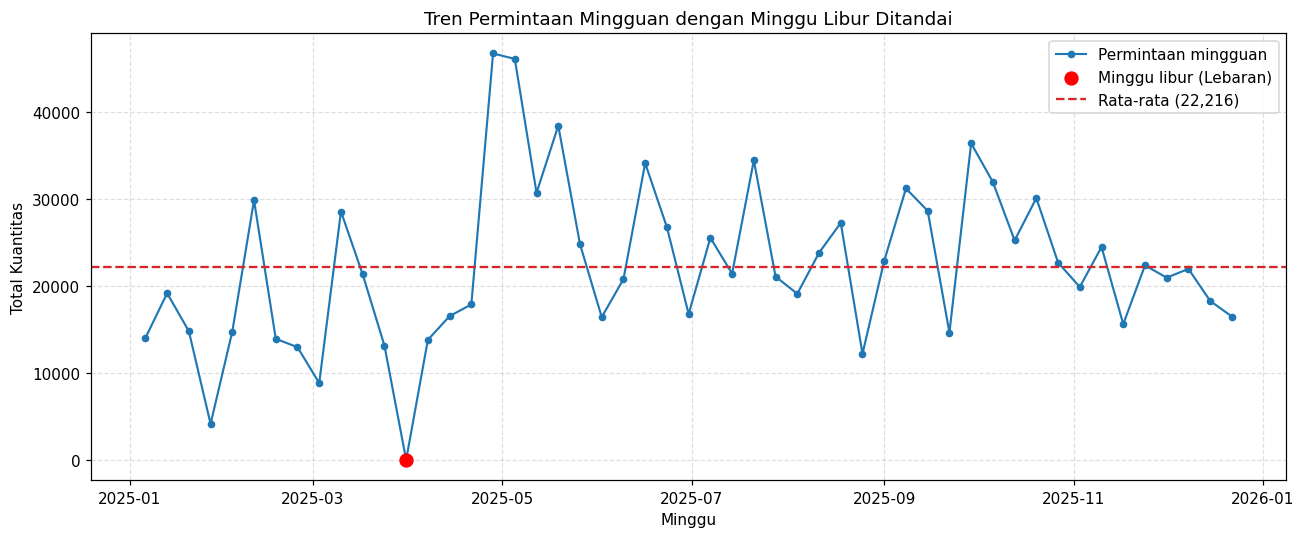

In [ ]:
# SEL 7 - Minggu libur panjang (Lebaran) + analisis sensitivitas
tg = np.sort(d['Tgl_Faktur'].dt.date.unique())
print("Hari faktur sekitar libur:",
      [t for t in tg if '2025-03-20' <= str(t) <= '2025-04-10'])

# Hari faktur terakhir sebelum libur = 28 Mar, pertama sesudah libur = 7 Apr
libur_awal, libur_akhir = pd.Timestamp('2025-03-28'), pd.Timestamp('2025-04-07')
n_in = ((d['Tgl_Faktur'] > libur_awal) & (d['Tgl_Faktur'] < libur_akhir)).sum()
print(f"Baris faktur antara {libur_awal.date()} dan {libur_akhir.date()}: {n_in} (sangat sedikit -> minggu libur)")

tutup = np.asarray(tgl == pd.Timestamp('2025-03-31'))
print("\nMinggu ditandai libur:\n", mg[tutup])
x_buka = x[~tutup]
print(f"\nSemua minggu ({n})  : mean {x.mean():,.0f}, SD {x.std(ddof=1):,.0f}, I = {x.var(ddof=1)/x.mean():.1f}")
print(f"Tanpa libur ({len(x_buka)}) : mean {x_buka.mean():,.0f}, SD {x_buka.std(ddof=1):,.0f}, I = {x_buka.var(ddof=1)/x_buka.mean():.1f}")
print("Ljung-Box p (semua)      :", round(acorr_ljungbox(x, lags=[10], return_df=True)['lb_pvalue'].iloc[0], 4))
print("Ljung-Box p (tanpa libur):", round(acorr_ljungbox(x_buka, lags=[10], return_df=True)['lb_pvalue'].iloc[0], 4))

gof_buka = uji_gof(x_buka)
display(gof_buka.round(4))
saran_buka = pilih(gof_buka)
print("Saran distribusi tanpa libur:", saran_buka)
tp = saran_buka or TERPILIH
print(f"Stok γ (semua minggu, {TERPILIH}) :", [float(stok(TERPILIH, x, g)) for g in G])
print(f"Stok γ (tanpa libur, {tp})  :", [float(stok(tp, x_buka, g)) for g in G])
print(f"Stok γ (tanpa libur, {TERPILIH}) :", [float(stok(TERPILIH, x_buka, g)) for g in G])

# Gambar tren dengan minggu libur ditandai
plt.figure(figsize=(12, 5))
plt.plot(tgl, x, marker='o', ms=4, lw=1.4, label='Permintaan mingguan')
plt.scatter(tgl[tutup], x[tutup], color='red', s=70, zorder=3, label='Minggu libur (Lebaran)')
plt.axhline(m, color='tab:red', ls='--', label=f'Rata-rata ({m:,.0f})')
plt.title('Tren Permintaan Mingguan dengan Minggu Libur Ditandai')
plt.xlabel('Minggu'); plt.ylabel('Total Kuantitas'); plt.legend(); plt.tight_layout(); plt.show()
